## Interval Analysis

In [6]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [7]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [8]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

0.01 70.55
0.02 23.68
0.03 4.56
0.04 0.58
0.05 0.02
0.06 0.0
0.07 0.0
0.08 0.0
0.09 0.0
0.1 0.0


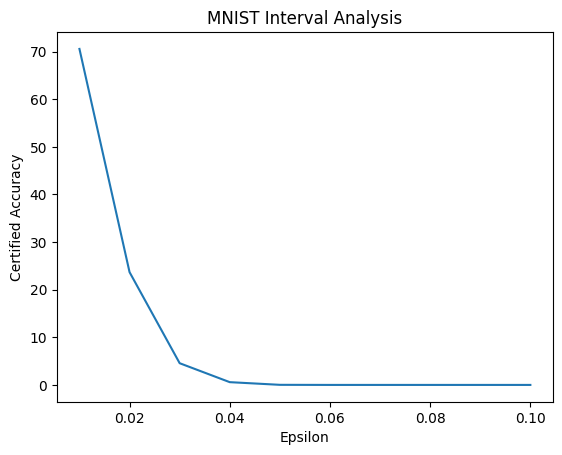

In [11]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

import torch
import matplotlib.pyplot as plt

def ibp_forward_linear_jit(weight, bias, center, diff):
    center, diff = center.unsqueeze(-2), diff.unsqueeze(-2)
    weight = weight.transpose(-1, -2)

    w_mid = center.matmul(weight)
    if bias is not None:
        w_mid = w_mid + bias.unsqueeze(-2)
    w_diff = diff.matmul(weight.abs())

    lower = w_mid - w_diff
    lower = lower.squeeze(-2)

    upper = w_mid + w_diff
    upper = upper.squeeze(-2)

    return lower, upper


def ibp_forward(lower, upper, layer):
    center = (lower + upper) / 2
    diff = (upper - lower) / 2
    lower, upper = ibp_forward_linear_jit(layer.weight, layer.bias, center, diff)

    return lower, upper


def from_eps(x, eps):
    lower, upper = x - eps, x + eps
    lower = torch.clamp(lower, 0, 1)
    upper = torch.clamp(upper, 0, 1)
    return lower, upper



def interval_analysis(images, eps):
    lower, upper = from_eps(images, eps)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(-1, 784)
    upper = upper.view(-1, 784)

    lower, upper = ibp_forward(lower, upper, model[1].fc)

    lower = torch.relu(lower)
    upper = torch.relu(upper)

    return lower, upper


def output_margins(lower, upper, labels):
    fc = model[1].fc2
    w = fc.weight
    b = fc.bias

    w_diff = w[labels][:, None, :] - w[None, :, :]
    b_diff = b[labels][:, None] - b[None, :]

    center = (lower + upper) / 2
    diff = (upper - lower) / 2

    lower, upper = ibp_forward_linear_jit(
        w_diff, b_diff, center, diff
    )

    return lower, upper

def certify(images, labels, eps):
    lower, upper = interval_analysis(images, eps)
    margins, _ = output_margins(lower, upper, labels)
    mask = torch.nn.functional.one_hot(labels, num_classes=10).bool()
    margins[mask] = float("inf")
    return torch.all(margins >= 0, dim=1)


epsilons = [0.01, 0.02, 0.03, 0.04, 0.05,
            0.06, 0.07, 0.08, 0.09, 0.10]
accuracies = []
for eps in epsilons:
    correct = 0
    total = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        result = certify(images, labels, eps)
        correct += result.sum().item()
        total += len(labels)

    accuracy = 100 * correct / total
    accuracies.append(accuracy)
    print(eps, accuracy)

plt.plot(epsilons, accuracies)
plt.xlabel("Epsilon")
plt.ylabel("Certified Accuracy")
plt.title("MNIST Interval Analysis")
plt.show()